# Module 1 — Dự đoán PM2.5 của giờ tiếp theo
Đây là **toàn bộ bài làm và phần huấn luyện** của Module 1. Đọc lời giải thích, chạy từng ô và xem kết quả ngay bên dưới.

- **Đầu vào:** các quan trắc tại giờ t, PM2.5 tại t−1, t−2, t−3, trạm và thông tin lịch.
- **Cần dự đoán:** PM2.5 đúng một giờ sau, tại cùng trạm.
- **Phương pháp:** Linear Regression, đối chiếu với persistence (giờ sau bằng giờ hiện tại).
- **Dữ liệu:** 12 file PRSA có sẵn trong `../data`; đơn vị thời gian là giờ Bắc Kinh.
- **Nguồn:** [UCI Beijing Multi-Site Air Quality](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality).

**Cách chạy:** chọn Run All, hoặc chạy `python run_module1.py`. Lệnh này thực sự chạy notebook, lưu lại kết quả vào chính notebook này, rồi mở ứng dụng.


## 1. Thư viện và các lựa chọn
Các lựa chọn của bài làm được đặt tại một chỗ. Chín biến số gồm sáu quan trắc hiện tại và ba giá trị PM2.5 trễ. Trạm, giờ, thứ trong tuần và tháng là các biến phân loại.

DEWP là **nhiệt độ điểm sương**, khác với độ ẩm tương đối. Nhiệt độ và điểm sương có thể âm.


In [1]:
%matplotlib inline
from pathlib import Path
from time import perf_counter
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Hỗ trợ mở notebook từ thư mục Module 1, ML hoặc btl.
candidates = [Path.cwd(), Path.cwd() / "Module 1", Path.cwd() / "ML" / "Module 1"]
MODULE_DIR = next((p.resolve() for p in candidates if (p / "module1.ipynb").is_file()), None)
if MODULE_DIR is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục Module 1, ML hoặc btl.")
DATA_DIR = MODULE_DIR.parent / "data"
OUTPUT_DIR = MODULE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
training_marker = OUTPUT_DIR / ".training"
training_marker.write_text("Notebook đang chạy; chạy lại nếu bị ngắt.", encoding="utf-8")

OBSERVATION_FEATURES = ["PM2.5", "PM10", "TEMP", "PRES", "DEWP", "WSPM"]
LAGS = [1, 2, 3]
NUMERIC_FEATURES = OBSERVATION_FEATURES + [f"PM25_lag_{lag}" for lag in LAGS]
CATEGORICAL_FEATURES = ["station", "hour", "day_of_week", "month"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "target_pm25"
TRAIN_END = "2015-11-01"
VALID_END = "2016-07-01"
UNITS = {
    "PM2.5": "µg/m³", "PM10": "µg/m³", "TEMP": "°C", "PRES": "hPa",
    "DEWP": "°C", "WSPM": "m/s",
    **{f"PM25_lag_{lag}": "µg/m³" for lag in LAGS},
}
pd.set_option("display.max_columns", 16)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Dữ liệu đầu vào:", DATA_DIR)
print("Thư mục lưu kết quả:", OUTPUT_DIR)


Dữ liệu đầu vào: G:\nam4ki1\hocmay\btl\ML\data
Thư mục lưu kết quả: G:\nam4ki1\hocmay\btl\ML\Module 1\outputs


## 2. Đọc và làm sạch dữ liệu
Chỉ đọc `PRSA_Data_*.csv`. Mỗi hàng là một quan trắc của một trạm tại một giờ.

Ta giữ lại hàng thiếu để ghép đúng mốc giờ ở bước 3. Giá trị thiếu, vô hạn hoặc sai miền được coi là thiếu; không nội suy từ tương lai. Các hàng trùng hoàn toàn được bỏ; trùng trạm/giờ nhưng khác giá trị sẽ báo lỗi để tránh chọn tùy ý.


In [2]:
def clean_observations(raw):
    frame = raw.copy()
    frame.columns = frame.columns.str.strip()
    required = ["station", *OBSERVATION_FEATURES]
    missing = [name for name in required if name not in frame]
    if missing:
        raise ValueError(f"Thiếu cột: {missing}")
    if "datetime" not in frame:
        calendar = ["year", "month", "day", "hour"]
        if not all(name in frame for name in calendar):
            raise ValueError("Cần datetime hoặc bốn cột year/month/day/hour.")
        frame["datetime"] = pd.to_datetime(frame[calendar], errors="coerce")
    else:
        frame["datetime"] = pd.to_datetime(frame["datetime"], errors="coerce")
    if not pd.api.types.is_datetime64_any_dtype(frame.datetime) or frame.datetime.dt.tz is not None:
        raise ValueError("datetime phải là giờ Bắc Kinh không gắn timezone.")
    frame["station"] = frame.station.astype("string").str.strip()
    valid = frame.datetime.notna() & frame.station.notna() & frame.station.ne("")
    valid &= frame.datetime.eq(frame.datetime.dt.floor("h"))
    frame = frame.loc[valid, ["station", "datetime", *OBSERVATION_FEATURES]].copy()
    for name in OBSERVATION_FEATURES:
        values = pd.to_numeric(frame[name], errors="coerce").astype(float)
        values = values.replace([np.inf, -np.inf], np.nan)
        if name in {"PM2.5", "PM10", "WSPM"}:
            values = values.mask(values < 0)
        if name == "PRES":
            values = values.mask(values <= 0)
        frame[name] = values
    frame = frame.drop_duplicates()
    if frame.duplicated(["station", "datetime"]).any():
        raise ValueError("Có trùng trạm/giờ nhưng khác giá trị; cần kiểm tra dữ liệu gốc.")
    if frame.empty:
        raise ValueError("Không còn quan trắc hợp lệ.")
    return frame.sort_values(["station", "datetime"]).reset_index(drop=True)

files = sorted(DATA_DIR.glob("PRSA_Data_*.csv"))
if not files:
    raise FileNotFoundError(f"Không tìm thấy dữ liệu PRSA tại {DATA_DIR}")
raw = pd.concat([pd.read_csv(file) for file in files], ignore_index=True)
observations = clean_observations(raw)
print(f"Đọc {len(files)} file, {len(raw):,} hàng gốc, {observations.station.nunique()} trạm.")
print("Thời gian:", observations.datetime.min(), "đến", observations.datetime.max())
display(observations.head())
display(pd.DataFrame({
    "Số giá trị thiếu/sai": observations[OBSERVATION_FEATURES].isna().sum(),
    "Tỷ lệ thiếu (%)": observations[OBSERVATION_FEATURES].isna().mean() * 100,
}).round(2))
display(observations[OBSERVATION_FEATURES].describe().round(2))


Đọc 12 file, 420,768 hàng gốc, 12 trạm.
Thời gian: 2013-03-01 00:00:00 đến 2017-02-28 23:00:00


,station,datetime,PM2.5,PM10,TEMP,PRES,DEWP,WSPM
0,Aotizhongxin,2013-03-01 00:00:00,4.0,4.0,-0.7,1023.0,-18.8,4.4
1,Aotizhongxin,2013-03-01 01:00:00,8.0,8.0,-1.1,1023.2,-18.2,4.7
2,Aotizhongxin,2013-03-01 02:00:00,7.0,7.0,-1.1,1023.5,-18.2,5.6
3,Aotizhongxin,2013-03-01 03:00:00,6.0,6.0,-1.4,1024.5,-19.4,3.1
4,Aotizhongxin,2013-03-01 04:00:00,3.0,3.0,-2.0,1025.2,-19.5,2.0


,Số giá trị thiếu/sai,Tỷ lệ thiếu (%)
PM2.5,8739,2.08
PM10,6449,1.53
TEMP,398,0.09
PRES,393,0.09
DEWP,403,0.10
WSPM,318,0.08


,PM2.5,PM10,TEMP,PRES,DEWP,WSPM
count,412029.00,414319.00,420370.00,420375.00,420365.00,420450.00
mean,79.79,104.60,13.54,1010.75,2.49,1.73
std,80.82,91.77,11.44,10.47,13.79,1.25
min,2.00,2.00,-19.90,982.40,-43.40,0.00
25%,20.00,36.00,3.10,1002.30,-8.90,0.90
50%,55.00,82.00,14.50,1010.40,3.10,1.40
75%,111.00,145.00,23.30,1019.00,15.10,2.20
max,999.00,999.00,41.60,1042.80,29.10,13.20


## 3. Tạo đầu vào và nhãn dự đoán
Ví dụ: tại **09:00**, đầu vào gồm quan trắc 09:00 và PM2.5 lúc 08:00, 07:00, 06:00. Nhãn cần học là PM2.5 lúc **10:00**, cùng trạm.

Tra cứu bằng **trạm + thời gian chính xác** giúp tránh ghép nhầm sang trạm khác hoặc vượt qua khoảng thời gian bị thiếu. Chỉ sau khi ghép xong ta mới loại mẫu chưa đủ đầu vào/nhãn. Thứ Hai được mã hóa là 0, Chủ nhật là 6.


In [3]:
def make_supervised(observations):
    result = observations.copy()
    lookup = observations.set_index(["station", "datetime"])["PM2.5"]
    if lookup.index.has_duplicates:
        raise ValueError("Dữ liệu phải duy nhất theo trạm/giờ.")
    for lag in LAGS:
        keys = pd.MultiIndex.from_arrays([
            result.station, result.datetime - pd.Timedelta(hours=lag)
        ])
        result[f"PM25_lag_{lag}"] = lookup.reindex(keys).to_numpy()
    result["target_datetime"] = result.datetime + pd.Timedelta(hours=1)
    next_keys = pd.MultiIndex.from_arrays([result.station, result.target_datetime])
    result[TARGET] = lookup.reindex(next_keys).to_numpy()
    result["hour"] = result.datetime.dt.hour
    result["day_of_week"] = result.datetime.dt.dayofweek
    result["month"] = result.datetime.dt.month
    result = result.dropna(subset=[*NUMERIC_FEATURES, TARGET])
    return result[["datetime", "target_datetime", *FEATURES, TARGET]].sort_values(
        ["target_datetime", "station"]
    ).reset_index(drop=True)

dataset = make_supervised(observations)
print(f"Còn {len(dataset):,} mẫu; loại {len(observations) - len(dataset):,} quan trắc chưa đủ dữ liệu.")
display(dataset.head())


Còn 401,095 mẫu; loại 19,673 quan trắc chưa đủ dữ liệu.


,datetime,target_datetime,PM2.5,PM10,TEMP,PRES,DEWP,WSPM,PM25_lag_1,PM25_lag_2,PM25_lag_3,station,hour,day_of_week,month,target_pm25
0,2013-03-01 03:00:00,2013-03-01 04:00:00,6.0,6.0,-1.4,1024.5,-19.4,3.1,7.0,8.0,4.0,Aotizhongxin,3,4,3,3.0
1,2013-03-01 03:00:00,2013-03-01 04:00:00,3.0,6.0,-3.6,1021.8,-19.1,1.0,3.0,3.0,3.0,Changping,3,4,3,3.0
2,2013-03-01 03:00:00,2013-03-01 04:00:00,6.0,6.0,-3.6,1021.8,-19.1,1.0,5.0,7.0,4.0,Dingling,3,4,3,5.0
3,2013-03-01 03:00:00,2013-03-01 04:00:00,3.0,3.0,-1.4,1026.2,-25.5,4.9,7.0,4.0,9.0,Dongsi,3,4,3,3.0
4,2013-03-01 03:00:00,2013-03-01 04:00:00,3.0,6.0,-1.4,1024.5,-19.4,3.1,3.0,4.0,4.0,Guanyuan,3,4,3,3.0


## 4. Chia train, validation và test theo thời gian
- **Train:** nhãn trước 01/11/2015 — dùng để học.
- **Validation:** nhãn từ 01/11/2015 đến trước 01/07/2016 — kiểm tra trên giai đoạn sau train.
- **Test:** nhãn từ 01/07/2016 — đánh giá cuối cùng.

Chia theo **giờ của nhãn** (`target_datetime`) để nhãn train không lọt sang giai đoạn validation. Không chia ngẫu nhiên chuỗi thời gian. Các mốc này thống nhất với phần dữ liệu của nhóm.


In [4]:
def split_by_time(dataset, train_end=TRAIN_END, valid_end=VALID_END):
    start_valid, start_test = pd.Timestamp(train_end), pd.Timestamp(valid_end)
    if (pd.isna(start_valid) or pd.isna(start_test) or start_valid.tzinfo is not None
            or start_test.tzinfo is not None or start_valid >= start_test):
        raise ValueError("Mốc chia phải hợp lệ, không timezone và train_end < valid_end.")
    time = dataset.target_datetime
    return {
        "train": dataset.loc[time < start_valid].copy(),
        "validation": dataset.loc[(time >= start_valid) & (time < start_test)].copy(),
        "test": dataset.loc[time >= start_test].copy(),
    }

splits = split_by_time(dataset)
for name, part in splits.items():
    missing_stations = set(observations.station.unique()) - set(part.station.unique())
    if len(part) < 2 or missing_stations:
        raise ValueError(f"Tập {name} thiếu dữ liệu hoặc thiếu trạm: {missing_stations}.")
display(pd.DataFrame([
    {"Tập": name, "Số mẫu": len(part),
     "Nhãn đầu": part.target_datetime.min(), "Nhãn cuối": part.target_datetime.max()}
    for name, part in splits.items()
]))


,Tập,Số mẫu,Nhãn đầu,Nhãn cuối
0,train,268501,2013-03-01 04:00:00,2015-10-31 23:00:00
1,validation,66031,2015-11-01 00:00:00,2016-06-30 23:00:00
2,test,66563,2016-07-01 00:00:00,2017-02-28 23:00:00


## 5. Huấn luyện Linear Regression
Pipeline có ba phần:
1. **StandardScaler:** chuẩn hóa chín biến số.
2. **OneHotEncoder:** mã hóa trạm và các biến lịch; bỏ một mức làm tham chiếu.
3. **LinearRegression:** học các hệ số hồi quy.

Dòng `pipeline.fit(...)` bên dưới là bước huấn luyện. Cả chuẩn hóa, mã hóa và hồi quy chỉ học từ **train**. Khi dự đoán, pipeline tự sử dụng lại đúng phép biến đổi đã học.

Công thức: $\hat{y} = \beta_0 + \sum_i \beta_i x_i$. Đây là mô hình tuyến tính, không có regularization.


In [5]:
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ("category", OneHotEncoder(drop="first", sparse_output=False,
                              handle_unknown="error"), CATEGORICAL_FEATURES),
])
pipeline = Pipeline([
    ("preprocess", preprocess),
    ("regression", LinearRegression()),
])

train = splits["train"]
fit_start = perf_counter()
pipeline.fit(train[FEATURES], train[TARGET])
fit_seconds = perf_counter() - fit_start
print(f"Đã huấn luyện trên {len(train):,} mẫu trong {fit_seconds:.2f} giây.")


Đã huấn luyện trên 268,501 mẫu trong 3.05 giây.


## 6. Đánh giá và đối chiếu với persistence
**Persistence** dự đoán PM2.5 giờ sau bằng PM2.5 hiện tại. Đây là đối chứng quan trọng vì hai giờ liền nhau thường có nồng độ gần nhau.

- **MAE:** sai số tuyệt đối trung bình; càng thấp càng tốt.
- **RMSE:** nhạy hơn với sai số lớn; càng thấp càng tốt.
- **R²:** mức độ giải thích biến thiên; càng cao càng tốt. R² có thể âm.
- MAE và RMSE có cùng đơn vị PM2.5: µg/m³.

Ta tính cho cả ba tập. Dự đoán của validation/test được giữ để xem biểu đồ và dùng trong ứng dụng. Test chỉ dùng đánh giá; cấu hình bài làm được cố định trước khi xem test.


In [6]:
def evaluate(actual, predicted):
    return {
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(root_mean_squared_error(actual, predicted)),
        "R2": float(r2_score(actual, predicted)),
    }

metric_rows, prediction_tables = [], []
for name, part in splits.items():
    predicted = pipeline.predict(part[FEATURES])
    baseline = part["PM2.5"].to_numpy()
    for model_name, values in [("Linear Regression", predicted), ("Persistence", baseline)]:
        metric_rows.append({
            "split": name, "model": model_name, "rows": len(part),
            **evaluate(part[TARGET], values),
        })
    if name != "train":
        # Giữ đầu vào để ứng dụng có thể lấy một mẫu thật và dự đoán lại.
        table = part[["station", "datetime", "target_datetime", *NUMERIC_FEATURES]].copy()
        table["split"] = name
        table["actual"] = part[TARGET].to_numpy()
        table["predicted"] = predicted
        table["baseline"] = baseline
        table["error"] = predicted - table.actual
        prediction_tables.append(table)

metrics = pd.DataFrame(metric_rows)
predictions = pd.concat(prediction_tables, ignore_index=True)
display(metrics.round(4))
print(metrics.to_string(index=False))
scores = metrics[metrics.split.eq("test")].set_index("model")
improvement = (1 - scores.loc["Linear Regression", "RMSE"] / scores.loc["Persistence", "RMSE"]) * 100
print(f"RMSE test cải thiện {improvement:.2f}% so với persistence.")
print("Sai số dương nghĩa là dự đoán cao hơn thực tế.")


,split,model,rows,MAE,RMSE,R2
0,train,Linear Regression,268501,10.3369,18.3903,0.9392
1,train,Persistence,268501,10.4241,19.3299,0.9329
2,validation,Linear Regression,66031,10.7026,20.0001,0.9534
3,validation,Persistence,66031,10.6753,21.0202,0.9486
4,test,Linear Regression,66563,10.3167,19.5076,0.9525
5,test,Persistence,66563,10.4541,20.6545,0.9468


     split             model   rows       MAE      RMSE       R2
     train Linear Regression 268501 10.336870 18.390321 0.939230
     train       Persistence 268501 10.424146 19.329891 0.932862
validation Linear Regression  66031 10.702599 20.000129 0.953443
validation       Persistence  66031 10.675274 21.020235 0.948573
      test Linear Regression  66563 10.316711 19.507568 0.952533
      test       Persistence  66563 10.454126 20.654497 0.946788
RMSE test cải thiện 5.55% so với persistence.
Sai số dương nghĩa là dự đoán cao hơn thực tế.


## 7. Xem và giải thích hệ số hồi quy
Với biến số, hệ số trong pipeline thể hiện thay đổi dự đoán khi biến tăng **một độ lệch chuẩn của train**, giữ các biến khác cố định. Chia hệ số này cho độ lệch chuẩn sẽ được hệ số theo **một đơn vị đo gốc**.

Với biến one-hot, hệ số được so với mức tham chiếu đã bỏ. Các đầu vào có tương quan với nhau, nên hệ số không chứng minh quan hệ nhân quả.


,feature,kind,coefficient,coefficient_per_unit,input_unit
0,PM2.5,numeric,79.191127,1.062370,µg/m³
1,PM10,numeric,3.885214,0.044534,µg/m³
2,TEMP,numeric,-3.074189,-0.283654,°C
3,PRES,numeric,0.269776,0.027176,hPa
4,DEWP,numeric,6.350159,0.468882,°C
5,WSPM,numeric,-2.179248,-1.772956,m/s
6,PM25_lag_1,numeric,-14.524683,-0.194810,µg/m³
7,PM25_lag_2,numeric,1.167284,0.015652,µg/m³
8,PM25_lag_3,numeric,0.376516,0.005051,µg/m³
9,station_Changping,category,1.228686,NaN,category


Hệ số chặn: 80.9351348744266
Mức tham chiếu: {'station': 'Aotizhongxin', 'hour': np.int32(0), 'day_of_week': np.int32(0), 'month': np.int32(1)}


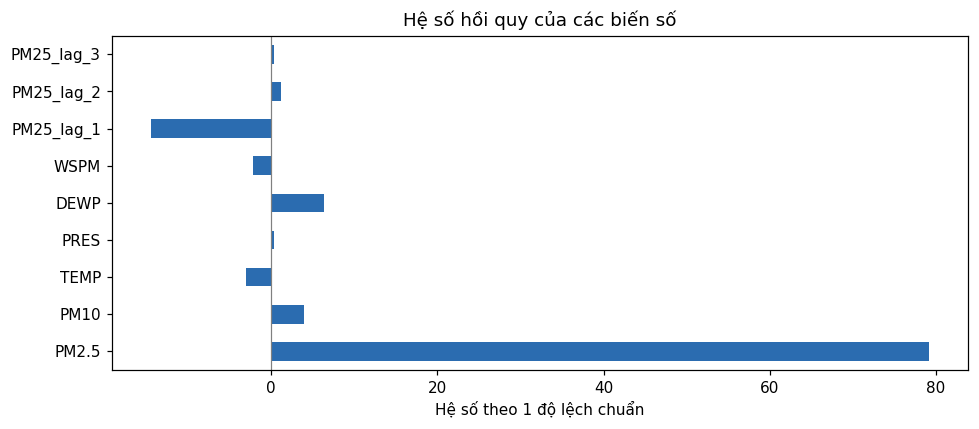

In [7]:
def coefficient_table(pipeline):
    fitted = pipeline.named_steps["preprocess"]
    weights = pipeline.named_steps["regression"].coef_
    scales = fitted.named_transformers_["numeric"].scale_
    rows = []
    for index, (name, weight) in enumerate(zip(fitted.get_feature_names_out(), weights)):
        numeric = index < len(NUMERIC_FEATURES)
        feature = name.split("__", 1)[1]
        rows.append({
            "feature": feature,
            "kind": "numeric" if numeric else "category",
            "coefficient": float(weight),
            "coefficient_per_unit": float(weight / scales[index]) if numeric else np.nan,
            "input_unit": UNITS.get(feature, "category"),
        })
    return pd.DataFrame(rows)

coefficients = coefficient_table(pipeline)
display(coefficients)
encoder = pipeline.named_steps["preprocess"].named_transformers_["category"]
print("Hệ số chặn:", pipeline.named_steps["regression"].intercept_)
print("Mức tham chiếu:", dict(zip(CATEGORICAL_FEATURES, [values[0] for values in encoder.categories_])))
numeric_coefficients = coefficients[coefficients.kind.eq("numeric")].set_index("feature")
fig, ax = plt.subplots(figsize=(9, 4))
numeric_coefficients.coefficient.plot.barh(ax=ax, color="#2B6CB0")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(title="Hệ số hồi quy của các biến số", xlabel="Hệ số theo 1 độ lệch chuẩn", ylabel="")
fig.tight_layout()
plt.show()


## 8. Biểu đồ đánh giá
Biểu đồ theo thời gian dùng trạm đầu tiên theo tên. Đường dự đoán/thực tế hiển thị 168 mẫu đầu của test để dễ đọc; biểu đồ phân tán lấy tối đa 5.000 mẫu từ toàn bộ test.

Biểu đồ sai số dùng toàn bộ test của trạm đang xem. Đường trung bình ngày giúp nhận ra giai đoạn mô hình thường dự đoán cao hoặc thấp. **Chỉ số ở bước 6 được tính trên toàn bộ mẫu**, không chỉ phần hiển thị.


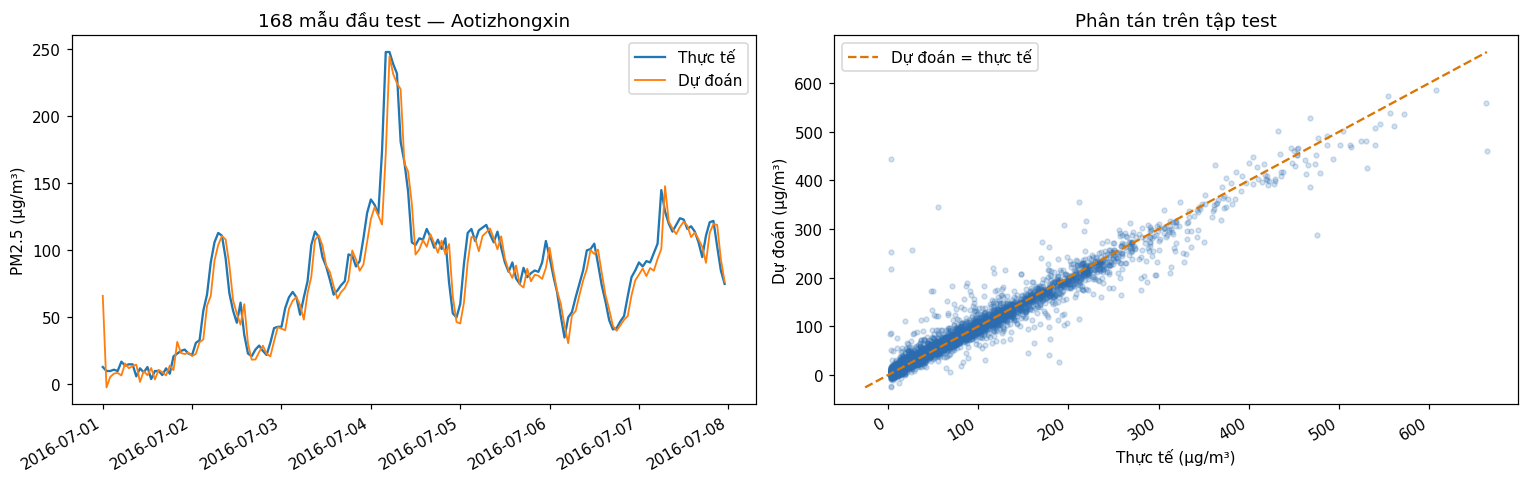

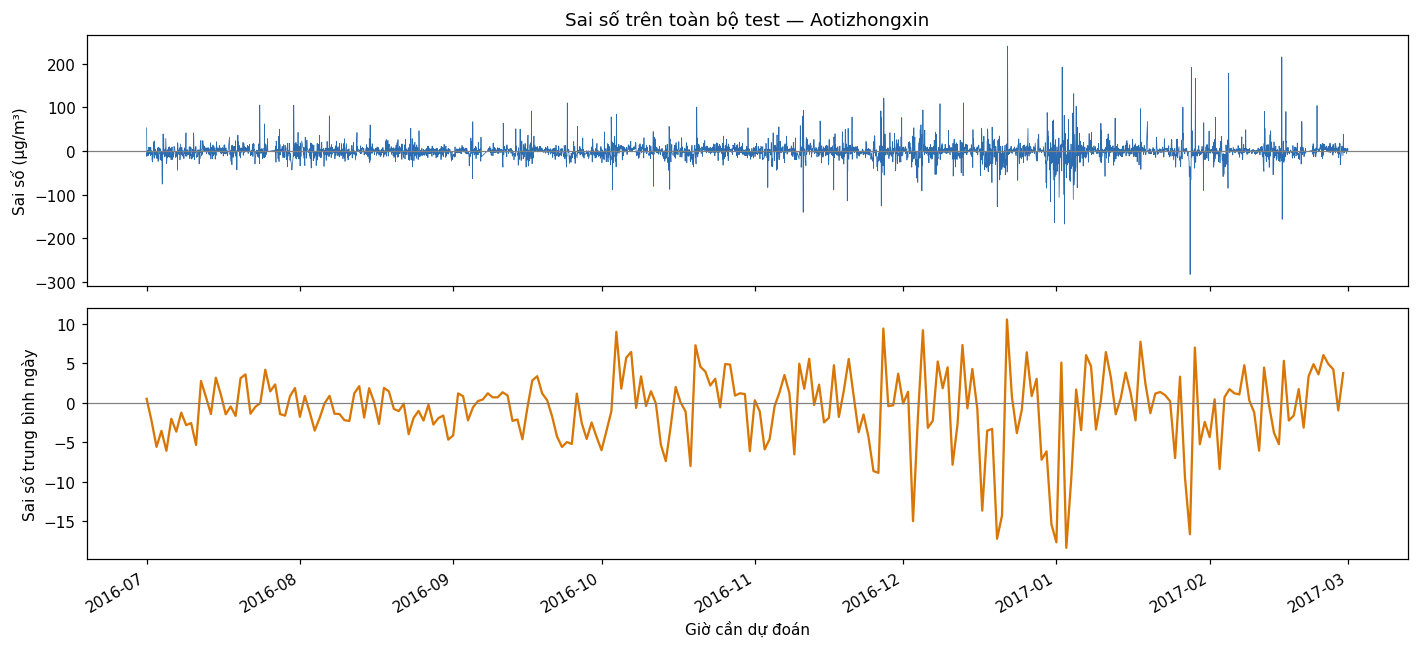

In [8]:
test_predictions = predictions[predictions.split.eq("test")]
plot_station = sorted(test_predictions.station.unique())[0]
station_predictions = test_predictions[test_predictions.station.eq(plot_station)].sort_values("target_datetime")
week = station_predictions.head(168)
scatter = test_predictions.sample(n=min(5000, len(test_predictions)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(week.target_datetime, week.actual, label="Thực tế", linewidth=1.5)
axes[0].plot(week.target_datetime, week.predicted, label="Dự đoán", linewidth=1.2)
axes[0].set(title=f"168 mẫu đầu test — {plot_station}", ylabel="PM2.5 (µg/m³)")
axes[0].legend()
axes[1].scatter(scatter.actual, scatter.predicted, alpha=0.2, s=10, color="#2B6CB0")
low = min(scatter.actual.min(), scatter.predicted.min())
high = max(scatter.actual.max(), scatter.predicted.max())
axes[1].plot([low, high], [low, high], "--", color="#D97706", label="Dự đoán = thực tế")
axes[1].set(title="Phân tán trên tập test", xlabel="Thực tế (µg/m³)", ylabel="Dự đoán (µg/m³)")
axes[1].legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(station_predictions.target_datetime, station_predictions.error, linewidth=0.5, color="#2B6CB0")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set(title=f"Sai số trên toàn bộ test — {plot_station}", ylabel="Sai số (µg/m³)")
daily_error = station_predictions.set_index("target_datetime").error.resample("D").mean()
axes[1].plot(daily_error.index, daily_error, color="#D97706")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set(ylabel="Sai số trung bình ngày", xlabel="Giờ cần dự đoán")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "error_over_time.png", dpi=160, bbox_inches="tight")
plt.show()


## 9. Lưu mô hình và kết quả
File `linear_regression.joblib` chứa pipeline đã học và các thông tin đầu vào để ứng dụng dùng lại đúng cách. `predictions.csv` giữ cả đầu vào, giá trị thực tế và dự đoán.

Sau bước này, `run_module1.py` mới mở `app.py`. Ứng dụng đọc những kết quả vừa lưu; bấm nút dự đoán chỉ gọi mô hình đã học.


In [9]:
model_info = {
    "pipeline": pipeline,
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "units": UNITS,
    "stations": sorted(observations.station.unique().tolist()),
    "split_rows": {name: len(part) for name, part in splits.items()},
    "train_end": TRAIN_END,
    "valid_end": VALID_END,
    "source": "https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality",
    "timezone": "Asia/Shanghai (UTC+8)",
}
metrics.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
coefficients.to_csv(OUTPUT_DIR / "coefficients.csv", index=False)
# Lưu mô hình sau cùng để ứng dụng nhận biết một lần chạy đã hoàn thành.
joblib.dump(model_info, OUTPUT_DIR / "linear_regression.joblib")
training_marker.unlink(missing_ok=True)
print("Đã lưu mô hình, 3 bảng CSV và 2 biểu đồ tại:", OUTPUT_DIR)
print("Có thể mở ứng dụng hoặc dùng hàm predict_pm25(input_data) trong app.py.")


Đã lưu mô hình, 3 bảng CSV và 2 biểu đồ tại: G:\nam4ki1\hocmay\btl\ML\Module 1\outputs
Có thể mở ứng dụng hoặc dùng hàm predict_pm25(input_data) trong app.py.


## 10. Các điểm cần nói khi báo cáo
- Bài toán là dự đoán PM2.5 **một giờ tiếp theo**, khác với phân loại mức ô nhiễm hay tính AQI.
- Giải thích một mẫu đầu vào, ba lag và nhãn bằng ví dụ giờ cụ thể.
- Nêu lý do chia theo thời gian và chỉ fit chuẩn hóa/mã hóa trên train.
- Đọc cả MAE, RMSE, R² và so sánh với persistence; mô hình có thể tốt hơn ở chỉ số này nhưng kém hơn ở chỉ số khác.
- Dùng hệ số và biểu đồ để giải thích hành vi, không suy diễn thành quan hệ nhân quả.
- Đây là dự báo cuốn từng giờ: tại mỗi giờ t đều có quan trắc thực mới đến t; không phải dự báo nhiều bước liên tiếp.
- Hạn chế: loại mẫu thiếu có thể gây thiên lệch; Linear Regression có thể bỏ lỡ đột biến và cho dự đoán âm; dữ liệu Bắc Kinh chưa đại diện cho Việt Nam. Dự đoán âm được giữ nguyên để đánh giá và giao diện nhất quán.

**Luồng duy nhất khi demo:** `run_module1.py → module1.ipynb → outputs → app.py`.
